# 02 · Forecasting national inflation

**Question.** Can a model forecast next year's (and the year after's) CPI
inflation for ~190 countries better than the naive benchmark, and can it say
how uncertain it is?

This notebook analyses the artefacts written by `python -m realgrowth_ml train`
(`data/models/inflation/`) rather than retraining, so every number here is the
number the website serves. See `docs/MODELING.md` for the design rationale.

**Protocol.** Rolling-origin backtest: for every origin year a fresh model is
trained only on rows whose *target* year was already observed. Hyperparameters
and the champion are chosen on forecasts made in 2001-2008 (validation); forecasts
made from 2009 onwards (test) are reported once and never used for selection.

In [1]:
import sys, json, sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = next(p for p in Path.cwd().resolve().parents if (p / "ml" / "src").is_dir())
sys.path.insert(0, str(ROOT / "ml" / "src"))
DB = ROOT / "data" / "realgrowth.db"
MODELS = ROOT / "data" / "models"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

def save(fig, name):
    path = FIG / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", dpi=130)
    plt.close(fig)
    display(Image(filename=str(path)))

In [2]:
card = json.loads((MODELS / "inflation" / "model_card.json").read_text())
backtest = pd.read_csv(MODELS / "inflation" / "backtest.csv")
forecasts = pd.read_csv(MODELS / "inflation" / "forecasts.csv")
names = {m["id"]: m["name"] for m in card["models"]}
print("champion:", names[card["champion"]])
print("design:", json.dumps({k: card["design"][k] for k in ["backtest", "selection_rule", "intervals"]}, indent=1))
print(f"{len(backtest):,} out-of-sample forecasts; tuned params: {card['models'][4]['card']['params']}")

champion: Ensemble (pooled AR + LightGBM)
design: {
 "backtest": "rolling origin, expanding window; train on rows with target year <= origin",
 "selection_rule": "lowest validation MAE (log scale) at h=1",
 "intervals": "Mondrian split conformal on log-scale absolute errors; rolling 10-year calibration window; bins by origin inflation [4.0, 10.0]"
}
62,292 out-of-sample forecasts; tuned params: {'h1': {'num_leaves': 15, 'min_child_samples': 60, 'n_estimators': 300}, 'h2': {'num_leaves': 7, 'min_child_samples': 60, 'n_estimators': 300}}


## 1. Leaderboard on the held-out test window

Scored on a common sample (every model forecast every cell). `skill` is the
reduction in log-scale MAE versus naive. Two baselines matter: naive (random
walk) and the pooled AR(3), the classical econometric benchmark.

In [3]:
m = pd.DataFrame(card["metrics"])
cols = ["n", "mae", "median_ae", "rmse", "mae_log", "skill_vs_naive", "coverage_80", "coverage_95", "median_width_80"]
for h in card["design"]["horizons"]:
    t = m[(m.window == "test") & (m.horizon == h)].set_index("model_id")[cols].sort_values("mae_log")
    t.index = [names.get(i, i) for i in t.index]
    print(f"\n=== {h} year(s) ahead, test window ===")
    display(t.round(3))


=== 1 year(s) ahead, test window ===


,n,mae,median_ae,rmse,mae_log,skill_vs_naive,coverage_80,coverage_95,median_width_80
Ensemble (pooled AR + LightGBM),2932,3.461,1.246,16.375,0.479,0.109,0.792,0.956,6.026
Pooled AR(3) ridge,2932,3.556,1.336,16.832,0.496,0.078,0.794,0.955,7.045
LightGBM global panel model,2932,3.631,1.289,16.813,0.501,0.069,0.781,0.958,5.768
LightGBM (inflation history only),2932,3.648,1.321,16.695,0.511,0.050,0.772,0.955,5.913
Naive (random walk),2932,3.746,1.438,16.366,0.538,0.000,0.798,0.957,8.112
Three-year mean,2932,4.035,1.607,17.501,0.572,-0.064,0.777,0.947,7.550



=== 2 year(s) ahead, test window ===


,n,mae,median_ae,rmse,mae_log,skill_vs_naive,coverage_80,coverage_95,median_width_80
Ensemble (pooled AR + LightGBM),2738,4.346,1.580,19.320,0.599,0.173,0.777,0.938,6.958
Pooled AR(3) ridge,2738,4.416,1.665,19.407,0.612,0.155,0.772,0.944,8.318
LightGBM global panel model,2738,4.401,1.599,19.263,0.620,0.144,0.769,0.936,6.407
Three-year mean,2738,4.596,1.780,19.465,0.642,0.114,0.764,0.945,8.226
LightGBM (inflation history only),2738,4.486,1.651,19.390,0.642,0.113,0.772,0.938,7.024
Naive (random walk),2738,5.208,1.995,21.565,0.724,0.000,0.772,0.947,10.989


**Reading the table.** The mean error in percentage points is dominated by a few
high-inflation country-years (RMSE ≫ MAE); the median error is the typical miss.
The ensemble has the lowest MAE, median error and log-scale MAE at both
horizons. RMSE, which is driven almost entirely by hyperinflation episodes, is
effectively tied across the stronger models (naive is marginally lowest at h=1).
The advantage over naive grows with the horizon, as expected: persistence decays
and mean reversion matters more two years out.

## 2. Is the improvement real? Diebold-Mariano tests

Errors are strongly correlated within a year (2022 surprised everyone), so the
loss differential is averaged per target year before testing; the unit of
evidence is ~15 years, not ~3,000 country-years. Newey-West variance with
`h-1` lags and the Harvey-Leybourne-Newbold small-sample correction.

In [4]:
dm = pd.DataFrame(card["significance"])
dm["versus"] = dm["versus"].map(names)
display(dm.round(3))

,horizon,versus,statistic,p_value,n_periods,mean_loss_diff
0,1,LightGBM global panel model,-1.369,0.191,16,-0.022
1,1,LightGBM (inflation history only),-1.275,0.222,16,-0.033
2,1,Three-year mean,-4.184,0.001,16,-0.095
3,1,Naive (random walk),-2.726,0.016,16,-0.059
4,1,Pooled AR(3) ridge,-1.115,0.282,16,-0.017
5,2,LightGBM global panel model,-1.457,0.167,15,-0.021
6,2,LightGBM (inflation history only),-2.349,0.034,15,-0.043
7,2,Three-year mean,-1.938,0.073,15,-0.044
8,2,Naive (random walk),-2.588,0.021,15,-0.127
9,2,Pooled AR(3) ridge,-0.659,0.520,15,-0.013


The champion beats the naive forecast significantly at both horizons
(p ≈ 0.02), the three-year mean at one year (p = 0.001), and the inflation-only
LightGBM at two years (p = 0.03). Against the pooled AR and the full LightGBM
model the gains are consistent in sign but not significant with only ~15 test
years. That is an honest result worth stating: the ensemble's main value over
its members is robustness, not a large accuracy jump.

## 3. Error over time

Median absolute error by target year. The 2021-23 inflation surge is a regime
change; every model (and, as widely documented, every central bank) under-predicted
it. The model recovers faster than naive once the surge is in the data.

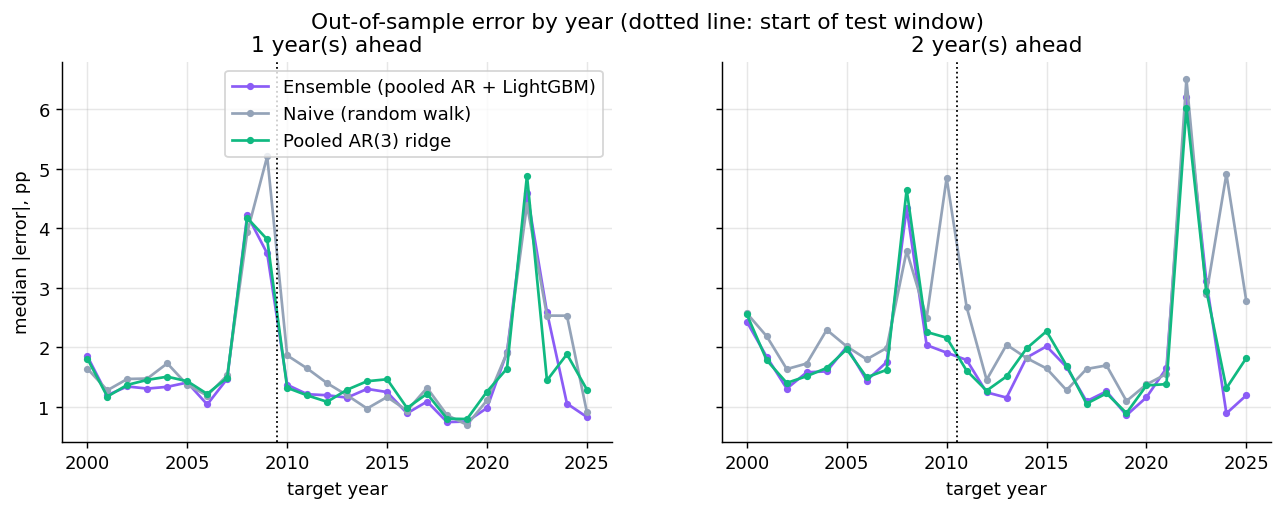

In [5]:
ye = pd.DataFrame(card["yearly_errors"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, h in zip(axes, [1, 2]):
    for mid, color in [(card["champion"], "#8b5cf6"), ("naive", "#94a3b8"), ("pooled_ar", "#10b981")]:
        d = ye[(ye.model_id == mid) & (ye.horizon == h) & (ye.target_year >= 2000)]
        ax.plot(d.target_year, d.median_ae, marker="o", ms=3, color=color, label=names[mid])
    ax.axvline(card["design"]["first_test_origin"] + h - 0.5, color="k", ls=":", lw=1)
    ax.set_title(f"{h} year(s) ahead"); ax.set_xlabel("target year")
axes[0].set_ylabel("median |error|, pp"); axes[0].legend()
fig.suptitle("Out-of-sample error by year (dotted line: start of test window)")
save(fig, "forecast_error_by_year")

## 4. Are the prediction intervals honest?

Intervals come from Mondrian split-conformal prediction: absolute log-scale
errors from the previous 10 observed years, calibrated separately by inflation
regime. A well-calibrated 80% interval should contain the outcome ~80% of the
time. Coverage by target year shows how the rolling window adapts after 2021.

overall test coverage (80% nominal): {1: 0.792, 2: 0.777}


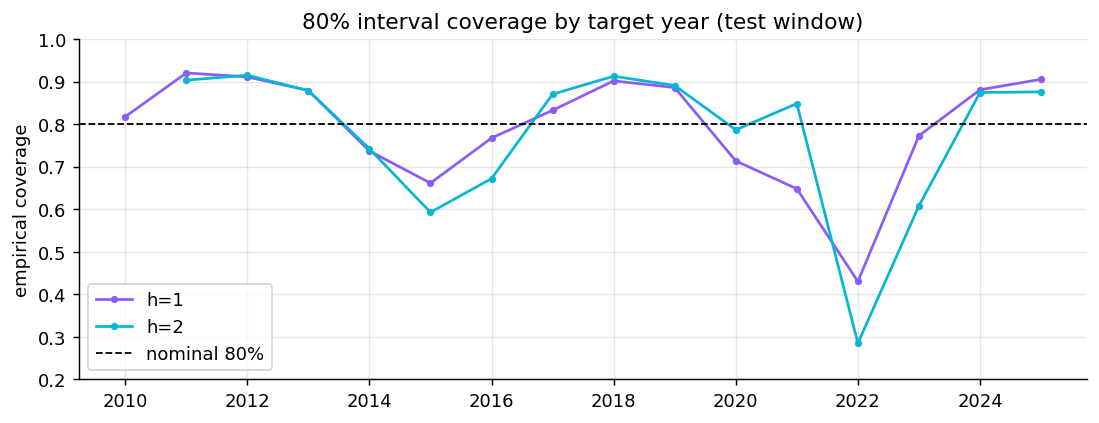

,model_id,horizon,regime,n,mae,median_ae,mae_log,coverage_80
0,ensemble,1,<4%,1716,1.632,0.964,0.508,0.769
1,ensemble,1,4-10%,870,2.521,1.453,0.391,0.830
2,ensemble,1,>10%,346,14.896,4.701,0.558,0.812
3,ensemble,2,<4%,1591,2.757,1.359,0.657,0.756
4,ensemble,2,4-10%,827,3.174,1.617,0.464,0.821
5,ensemble,2,>10%,320,15.276,3.989,0.662,0.769
6,naive,1,<4%,1716,1.800,1.059,0.588,0.786
7,naive,1,4-10%,870,2.807,1.717,0.430,0.810
8,naive,1,>10%,346,15.761,5.746,0.559,0.832
9,naive,2,<4%,1591,2.974,1.489,0.780,0.764


In [6]:
champ = backtest[(backtest.model_id == card["champion"]) & backtest.lower_80.notna()].copy()
champ["inside"] = (champ.actual >= champ.lower_80) & (champ.actual <= champ.upper_80)
test = champ[champ.origin_year >= card["design"]["first_test_origin"]]
by_year = test.groupby(["horizon", "target_year"]).inside.mean().unstack(0)
print("overall test coverage (80% nominal):", test.groupby("horizon").inside.mean().round(3).to_dict())
fig, ax = plt.subplots(figsize=(10, 3.4))
for h, color in [(1, "#8b5cf6"), (2, "#06b6d4")]:
    ax.plot(by_year.index, by_year[h], marker="o", ms=3, color=color, label=f"h={h}")
ax.axhline(0.8, color="k", ls="--", lw=1, label="nominal 80%")
ax.set_ylim(0.2, 1.0); ax.set_ylabel("empirical coverage"); ax.legend()
ax.set_title("80% interval coverage by target year (test window)")
save(fig, "forecast_coverage_by_year")
display(pd.DataFrame(card["regimes"]).round(3))

Coverage is close to nominal over the whole test window (79% and 78% for the
80% interval) and within a few points of it in each inflation regime, which is
what Mondrian calibration is for: one pooled interval would be too wide for
Switzerland and too narrow for Argentina.

Year by year it is a different story, and the chart is the honest view.
Conformal prediction guarantees *average* coverage under exchangeability, not
coverage in every year. When the world changes faster than a 10-year
calibration window, coverage drops: in 2015 (oil-price collapse and deflation)
and above all in 2022, when only 43% (h=1) and 28% (h=2) of outcomes fell inside
the 80% interval. It then recovers to ~90% by 2024-25 as the surge enters the
calibration set. This is the expected failure mode of any method that assumes
the near future resembles the recent past, and it is listed in the model card.

## 5. What drives the forecasts?

Mean absolute TreeSHAP value per feature across current forecasts (the
ensemble's attributions are the average of its members': exact SHAP for the
linear model, TreeSHAP for LightGBM).

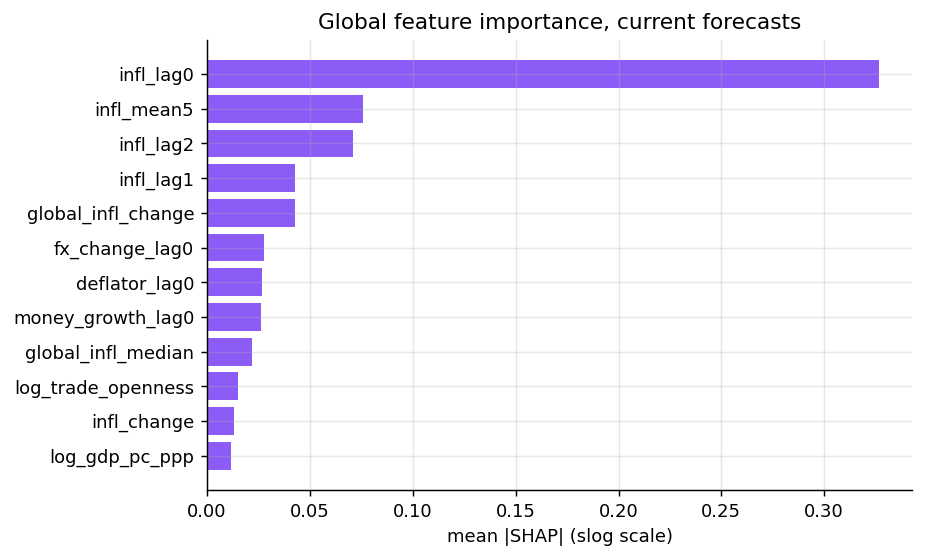

In [7]:
imp = pd.DataFrame(card["global_importance"]).set_index("feature")["mean_abs_shap"].head(12)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.index, imp.values, color="#8b5cf6"); ax.set_xlabel("mean |SHAP| (slog scale)")
ax.set_title("Global feature importance, current forecasts")
save(fig, "forecast_feature_importance")

Current inflation dominates, as the EDA predicted; history (5-year mean, lags),
the global cycle and then money growth, depreciation and the deflator follow.
The inflation-only ablation in the leaderboard quantifies what the macro
features add on top.

## 6. Current forecasts against the IMF

The IMF's World Economic Outlook is produced by country economists with far
richer information (monthly data, policy plans). Historical WEO vintages are not
scriptably downloadable, so this is a side-by-side comparison of *current*
forecasts, not a backtest.

166 countries · rank corr 0.78 · median |ours - IMF| 1.00pp · IMF inside our 80% interval: 95%


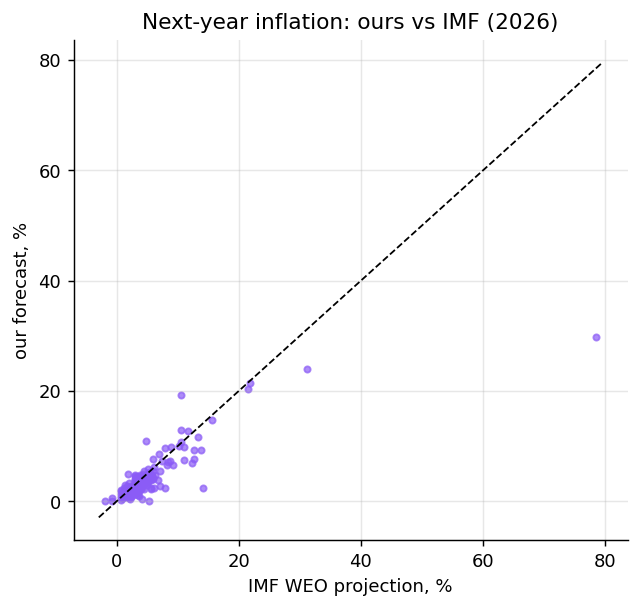

In [8]:
imf = pd.read_csv(ROOT / "data" / "raw" / "api" / "imf_inflation_forecast.csv")
ours = forecasts[forecasts.horizon == 1][["iso3", "target_year", "point", "lower_80", "upper_80"]]
both = ours.merge(imf, left_on=["iso3", "target_year"], right_on=["iso3", "year"])
both = both[both.point.abs() < 60]
inside = ((both.value >= both.lower_80) & (both.value <= both.upper_80)).mean()
print(f"{len(both)} countries · rank corr {both.point.corr(both.value, method='spearman'):.2f} · "
      f"median |ours - IMF| {np.median(np.abs(both.point - both.value)):.2f}pp · "
      f"IMF inside our 80% interval: {inside:.0%}")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(both.value, both.point, s=12, alpha=0.7, color="#8b5cf6")
lim = [min(both.value.min(), both.point.min()) - 1, max(both.value.max(), both.point.max()) + 1]
ax.plot(lim, lim, "k--", lw=1); ax.set_xlabel("IMF WEO projection, %"); ax.set_ylabel("our forecast, %")
ax.set_title(f"Next-year inflation: ours vs IMF ({int(both.target_year.mode()[0])})")
save(fig, "forecast_vs_imf")

## 7. Example: fan charts

History plus forecast with 80% and 95% intervals and the IMF projection.

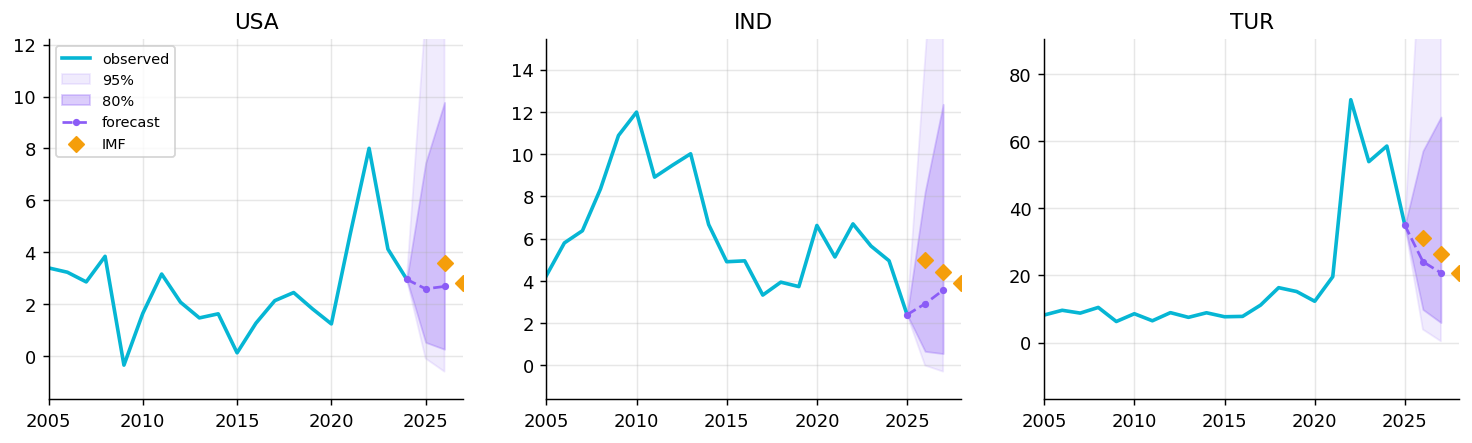

In [9]:
infl = pd.read_sql("SELECT iso3, year, value FROM observations WHERE indicator_id='inflation_rate'",
                   sqlite3.connect(DB)).pivot(index="iso3", columns="year", values="value")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, iso3 in zip(axes, ["USA", "IND", "TUR"]):
    h = infl.loc[iso3].dropna().loc[2005:]
    f = forecasts[forecasts.iso3 == iso3].sort_values("target_year")
    x = [h.index[-1], *f.target_year]
    ax.plot(h.index, h.values, color="#06b6d4", lw=2, label="observed")
    ax.fill_between(x, [h.iloc[-1], *f.lower_95], [h.iloc[-1], *f.upper_95], color="#8b5cf6", alpha=0.12, label="95%")
    ax.fill_between(x, [h.iloc[-1], *f.lower_80], [h.iloc[-1], *f.upper_80], color="#8b5cf6", alpha=0.3, label="80%")
    ax.plot(x, [h.iloc[-1], *f.point], color="#8b5cf6", ls="--", marker="o", ms=3, label="forecast")
    i = imf[imf.iso3 == iso3]
    ax.scatter(i.year, i.value, marker="D", color="#f59e0b", zorder=3, label="IMF")
    ax.set_title(iso3); ax.set_xlim(2005, x[-1] + 1)
    # Cap the axis at the 80% band so a wide 95% band does not flatten the history.
    ax.set_ylim(top=max(h.max(), f.upper_80.max(), i.value.max() if len(i) else 0) * 1.25)
axes[0].legend(fontsize=8)
save(fig, "forecast_fan_charts")

## 8. Error analysis: the biggest misses

Where does the champion fail worst (test window, 1 year ahead)?

In [10]:
c = backtest[(backtest.model_id == card["champion"]) & (backtest.horizon == 1) &
             (backtest.origin_year >= card["design"]["first_test_origin"])].copy()
c["error"] = c.actual - c.point
display(c.reindex(c.error.abs().sort_values(ascending=False).index).head(12)
        [["iso3", "origin_year", "target_year", "point", "actual", "error"]].round(1))
print("share of test forecasts that under-predicted:", round((c.error > 0).mean(), 3))

,iso3,origin_year,target_year,point,actual,error
56319,ZWE,2019,2020,55.1,557.2,502.1
55556,SSD,2015,2016,15.2,380.0,364.8
56461,SDN,2020,2021,80.2,359.1,278.9
56141,ZWE,2018,2019,5.3,255.3,250.0
55582,VEN,2015,2016,49.3,254.9,205.6
56769,LBN,2022,2023,60.2,221.3,161.2
56858,ARG,2023,2024,81.7,219.9,138.2
56283,SDN,2019,2020,30.0,163.3,133.3
56412,LBN,2020,2021,29.2,154.8,125.6
56591,LBN,2021,2022,50.1,171.2,121.1


share of test forecasts that under-predicted: 0.563


The largest misses are currency crises and hyperinflation onsets (Zimbabwe,
South Sudan, Sudan, Venezuela, Lebanon, Argentina): events driven by policy and
balance-of-payments shocks that annual macro aggregates do not anticipate. The
model card lists this as the main limitation; the high-inflation regime is also
where its intervals are widest by design.

## Conclusions

* A pooled ensemble of a linear AR model and a global LightGBM model beats the
  naive benchmark by ~11% (1 year) and ~17% (2 years) on log-scale MAE out of
  sample, significant at 5% by Diebold-Mariano on per-year losses.
* Mondrian conformal intervals achieve near-nominal coverage on average and per
  inflation regime, but not in every year: coverage collapsed during the 2022
  surge before recovering.
* Forecasts rank countries similarly to the IMF (Spearman ≈ 0.78), and the IMF
  projection falls inside our 80% interval for most countries.
* The main failure mode is crisis onset, which no annual-data model can foresee.